# Creating PandaICT Networks

This Tutorial will introduce the user into the pandaict datastructure and how to create networks through the pandaict API. The following minimal example contains the most common elements that are supported by the Pandaict format.

The datastructure of the pandaict framework is based on the python library pandas. A pandaict network consist of a separate element table for each element type that is used in the network. Each element table consists of a column for each parameter and a row for each element. By executing the follwing code cells you generate the various element tables. You can find detailed descriptions about each parameter in the pandapower documentation under bulletpoint "Datastructures and Elements".

## Empty Network

In [1]:
import pandaict as pi #import pandaict

ict_net = pi.create_empty_ict_network() #create an empty network

## ICT - Node

We now create six ICT Nodes



In [2]:
# create_ict_node(net, type=None, name=None, index=None, in_service=True)
node1 = pi.create_ict_node(ict_net, name="ICT Node 1")
node2 = pi.create_ict_node(ict_net, name="ICT Node 2")
node3 = pi.create_ict_node(ict_net, name="ICT Node 3")
node4 = pi.create_ict_node(ict_net, name="ICT Node 4")
node5 = pi.create_ict_node(ict_net, name="ICT Node 5")
node6 = pi.create_ict_node(ict_net, name="ICT Node 6")

In [3]:
ict_net.node #show node table

,name,type,in_service
0,ICT Node 1,None,True
1,ICT Node 2,None,True
2,ICT Node 3,None,True
3,ICT Node 4,None,True
4,ICT Node 5,None,True
5,ICT Node 6,None,True


## ICT - Link

We now create link connections between the Nodes

In [4]:
# create_ict_link(net, from_node, to_node, length_km, protocols, type="wired", name=None, index=None, in_service=True)
link1 = pi.create_ict_link(ict_net, node1, node2, protocols="TCP", length_km=1.0, type="wired", name="Link 1")
link2 = pi.create_ict_link(ict_net, node2, node3, protocols="TCP", length_km=1.0, type="wired", name="Link 2")
link3 = pi.create_ict_link(ict_net, node3, node4, protocols="TCP", length_km=1.0, type="wired", name="Link 3")
link4 = pi.create_ict_link(ict_net, node4, node5, protocols="TCP", length_km=1.0, type="wired", name="Link 4")
link5 = pi.create_ict_link(ict_net, node5, node6, protocols="TCP", length_km=1.0, type="wireless", name="Link 5")
link6 = pi.create_ict_link(ict_net, node6, node1, protocols="TCP", length_km=1.0, type="wireless", name="Link 6")

Link 5 and link 6 are classified as wireless links (type="wireless"), all other links are classified as wired links (type="wired")

In [5]:
ict_net.link #show link table

,name,from_node,to_node,length_km,type,protocols,in_service
0,Link 1,0,1,1.0,wired,TCP,True
1,Link 2,1,2,1.0,wired,TCP,True
2,Link 3,2,3,1.0,wired,TCP,True
3,Link 4,3,4,1.0,wired,TCP,True
4,Link 5,4,5,1.0,wireless,TCP,True
5,Link 6,5,0,1.0,wireless,TCP,True


## ICT - Device

We now create Devices connectec to the nodes

In [6]:
# create_ict_device(net, node, protocol, service, interconnects, name=None, index=None, type=None, in_service=True)
device1 = pi.create_ict_device(ict_net, node1, protocol="TCP", service=1, interconnects="placeholder")
device2 = pi.create_ict_device(ict_net, node2, protocol="TCP", service=1, interconnects="placeholder")
device4 = pi.create_ict_device(ict_net, node4, protocol="TCP", service=1, interconnects="placeholder")
device5 = pi.create_ict_device(ict_net, node5, protocol="TCP", service=1, interconnects="placeholder")
device6 = pi.create_ict_device(ict_net, node6, protocol="TCP", service=1, interconnects="placeholder")

## ICT - Node Geodata

We give the created nodes geodata for the plot

In [7]:
ict_net.node_geodata.loc[0, ["x", "y"]] = (0, 0)
ict_net.node_geodata.loc[1, ["x", "y"]] = (1, 0)
ict_net.node_geodata.loc[2, ["x", "y"]] = (1, 1)
ict_net.node_geodata.loc[3, ["x", "y"]] = (1, 2)
ict_net.node_geodata.loc[4, ["x", "y"]] = (0, 2)
ict_net.node_geodata.loc[5, ["x", "y"]] = (0, 1)

## Plot ICT - Network

<AxesSubplot:>

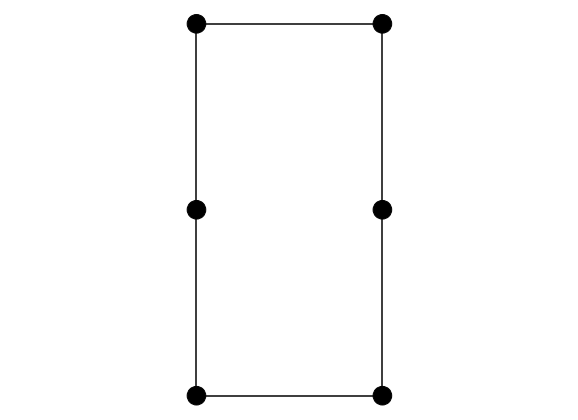

In [9]:
import pandapower.plotting as plot

pc = pi.create_ict_node_collection(ict_net, size= 0.05, color="black")
lc = pi.create_ict_link_collection(ict_net, color="black")

plot.draw_collections([lc, pc], figsize=(8,6))